In [1]:

%matplotlib inline
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.inspection import PartialDependenceDisplay
from sklearn.model_selection import train_test_split


# Partial Dependence Plots

In [3]:
bike_day_df_raws = pd.read_csv('./bsd/day.csv')
bike_day_df_raws.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [4]:
# Keep only some features
df = bike_day_df_raws[["temp", "hum", "windspeed", "cnt"]]

# Train test split

X_train, X_test, y_train, y_test = train_test_split(df.iloc[:, :3], # train for first 3 variables
                                                    df.iloc[:, 3], # test is the last variable
                                                    test_size=0.2, # 20% for testing
                                                    random_state = 123)

# Fit model by default
model = GradientBoostingRegressor(random_state = 123)
model.fit(X_train, y_train)

# Evaluate model using R squared
score = model.score(X_test, y_test)
score

0.4521661939298667

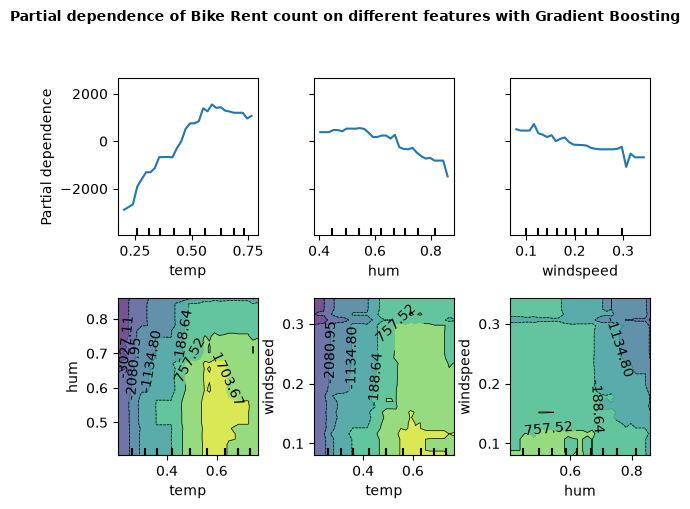

In [5]:
# Create the partial dependence display
pdp = PartialDependenceDisplay.from_estimator(model, 
                                              X_train, 
                                              features = ["temp", "hum", "windspeed", 
                                                          ("temp", "hum"), ("temp", "windspeed"), ("hum", "windspeed")], 
                                              #kind="both", 
                                              grid_resolution=30)

# Adjust the subplots spacing
pdp.figure_.subplots_adjust(wspace=0.4, hspace=0.4)

# Set the suptitle
plt.suptitle("Partial dependence of Bike Rent count on different features with Gradient Boosting", y=1.05, fontsize=10, fontweight='bold')

# Tighten the layout
plt.tight_layout()

In [ ]:
X_test

,temp,hum,windspeed
488,0.560000,0.768333,0.133696
421,0.279167,0.410000,0.205229
91,0.315000,0.653750,0.197146
300,0.330833,0.585833,0.229479
177,0.682500,0.658333,0.107588
...,...,...,...
631,0.529167,0.467083,0.223258
548,0.781667,0.447083,0.195267
439,0.557500,0.579583,0.149883
449,0.437500,0.880833,0.220775


In [7]:
from sklearn.inspection import partial_dependence
ice_df = partial_dependence(model, X_test, ['temp'], kind='individual')


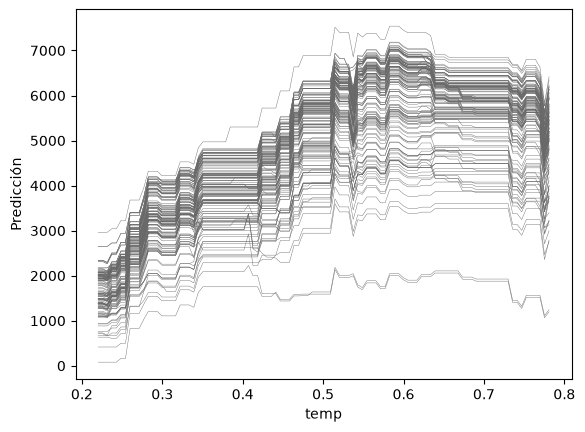

In [8]:
plt.plot(ice_df['grid_values'][0], ice_df['individual'][0].T, c='dimgray', linewidth=0.3)
plt.ylabel('Predicción')
plt.xlabel('temp');

# LIME para clasificación de imágenes

In [10]:
! pip install scikit-image
! pip install torch
! pip install keras

  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   -- ------------------------------------- 9.4/126.7 MB 63.3 MB/s eta 0:00:02
   ---- ----------------------------------- 14.4/126.7 MB 36.2 MB/s eta 0:00:04
   ------- -------------------------------- 22.3/126.7 MB 39.8 MB/s eta 0:00:03
   --------- ------------------------------ 30.4/126.7 MB 37.1 MB/s eta 0:00:03
   ------------ --------------------------- 41.2/126.7 MB 40.1 MB/s eta 0:00:03
   ----------------- ---------------------- 55.3/126.7 MB 45.1 MB/s eta 0:00:02
   ---------------------- ----------------- 70.0/126.7 MB 49.0 MB/s eta 0:00:02
   -------------------------- ------------- 83.6/126.7 MB 51.3 MB/s eta 0:00:01
   ------------------------------ --------- 96.2/126.7 MB 52.5 MB/s eta 0:00:01
   ---------------------------------- ---- 111.9/126.7 MB 55.0 MB/s eta 0:00:01
   --------------------------------------  126.6/126.7 MB 56.9

In [11]:
import os
os.environ["KERAS_BACKEND"] = "torch"


In [12]:
from keras.applications import inception_v3 as inc_net
from keras.preprocessing import image
from keras.applications.imagenet_utils import decode_predictions
from skimage.io import imread
import skimage

In [14]:
! pip install lime

In [15]:
import lime
from lime import lime_image
from keras.applications.inception_v3 import InceptionV3, preprocess_input
from keras.preprocessing import image
import numpy as np

c:\Users\uo282000\Desktop\Inteligencia de Negocio\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [16]:
# Load and preprocess the image
image_path = './bsd/Dog_cat_1.png'  
# image_path = './bsd/Dog_cat_2.jpg'  
img = image.load_img(image_path, target_size=(299, 299))
x = image.img_to_array(img)
x = np.expand_dims(x, axis=0)
x = preprocess_input(x)

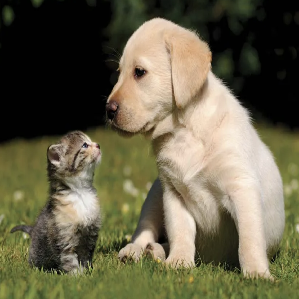

In [17]:
img

In [18]:
# Clasificador de imágenes preentrenado

inet_model = InceptionV3()


96112376/96112376 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [19]:
def load_imagenet_labels(file_path):
    with open(file_path, 'r') as f:
        labels = [line.strip() for line in f.readlines()]
    return labels

# Example usage
file_path = './bsd/imagenet1000_clsidx_to_labels.txt'
imagenet_labels = load_imagenet_labels(file_path)

In [20]:
# Función que toma una imagen y produce las probabilidades de que pertenezca a cada clase

explainer = lime_image.LimeImageExplainer()
def predict_fn(images):
    return inet_model.predict(images)

In [21]:
! pip install ipywidgets

   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 2.2/2.2 MB 14.1 MB/s  0:00:00

   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   ---------------------------------------- 3/3 [ipywidgets]



In [23]:
# Se le pasa una imagen, el color que se le pone a los pixeles cuando se ocultan, y el número de muestras
# perturbadas que se generan para evaluar cómo cambia el clasificador cuando se ocultan puntos

explanation = explainer.explain_instance(x[0], 
                                         predict_fn, 
                                         top_labels=5, 
                                         hide_color=0, 
                                         num_samples=2000,
                                         batch_size=100)

  4%|▍         | 84/2000 [00:00<00:04, 418.76it/s]

4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step


  8%|▊         | 162/2000 [00:06<01:21, 22.52it/s]

4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step


 14%|█▍        | 276/2000 [00:12<01:07, 25.50it/s]

4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step


... (31 outputs left out)

4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step


 98%|█████████▊| 1970/2000 [02:03<00:01, 22.29it/s]

4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step


100%|██████████| 2000/2000 [02:09<00:00, 15.41it/s]


In [24]:
[imagenet_labels[i] for i in explanation.top_labels]

["208: 'Labrador retriever',",
 "207: 'golden retriever',",
 "216: 'clumber, clumber spaniel',",
 "215: 'Brittany spaniel',",
 "852: 'tennis ball',"]

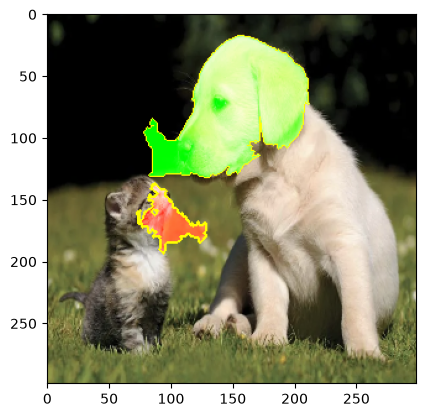

In [21]:
# Muestra las regiones que más contribuyen a la primera predicción

from skimage.segmentation import mark_boundaries

# Display the explanation using matplotlib
temp, mask = explanation.get_image_and_mask(explanation.top_labels[0], 
                                            positive_only=False, 
                                            num_features=5, 
                                            hide_rest=False)
plt.imshow(mark_boundaries(temp / 2 + 0.5, mask))

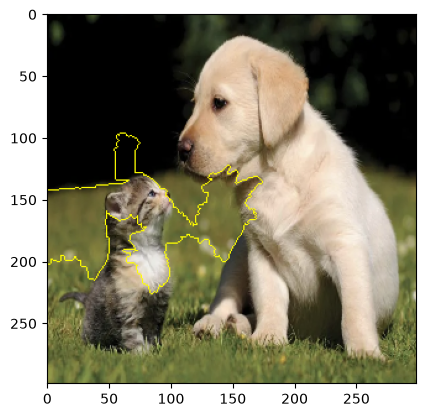

In [22]:
# Muestra las regiones que más se oponen a la primera predicción

from skimage.segmentation import mark_boundaries

# Display the explanation using matplotlib
temp, mask = explanation.get_image_and_mask(explanation.top_labels[0], 
                                            positive_only=False,
                                            negative_only=True, 
                                            num_features=5, 
                                            hide_rest=False)
plt.imshow(mark_boundaries(temp / 2 + 0.5, mask))

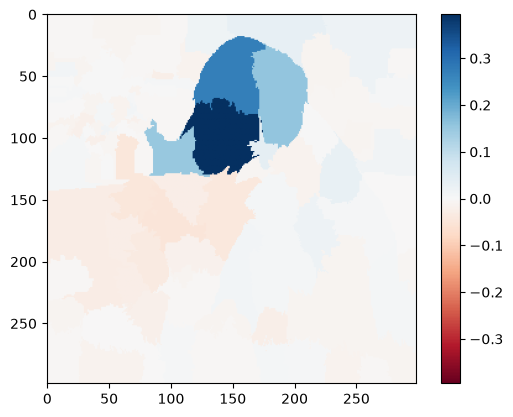

In [23]:
ind = explanation.top_labels[0]

dict_heatmap = dict(explanation.local_exp[ind])
heatmap = np.vectorize(dict_heatmap.get)(explanation.segments)

plt.imshow(heatmap, cmap='RdBu', vmin= -heatmap.max(), vmax = heatmap.max())
plt.colorbar()

In [25]:
X_train.columns.values.tolist()

['temp', 'hum', 'windspeed']

# Lime para datos tabulares

In [25]:


from sklearn.datasets import load_iris
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from lime import lime_tabular

# Cargar el conjunto de datos Iris
data = load_iris()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Dividir los datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# Entrenar un clasificador de bosque aleatorio
clf = RandomForestClassifier(n_estimators=100)
clf.fit(X_train.values, y_train)

# Crear un explainer de LIME para datos tabulares
explainer = lime_tabular.LimeTabularExplainer(X_train.values, 
                                              feature_names=X_train.columns, 
                                              class_names=data.target_names, 
                                              mode='classification')

# Seleccionar una instancia para explicar
i = 1

# Explicar la instancia
exp = explainer.explain_instance(X_test.iloc[i].values, clf.predict_proba, num_features=4, labels=[0,1,2])



In [26]:
print("Predicción del modelo para la instancia:", data.target_names[clf.predict([X_test.iloc[i].values])[0]])

Predicción del modelo para la instancia: setosa


In [27]:
clf.predict_proba(X_test.iloc[i].values.reshape(1, -1))

array([[0.98, 0.02, 0.  ]])

In [28]:
# Mostrar la explicación
from IPython.display import HTML, display
display(HTML(exp.as_html(show_table=True)))  # show_in_notebook() falla con IPython 9

In [29]:
X_test.iloc[i]

sepal length (cm)    5.7
sepal width (cm)     3.8
petal length (cm)    1.7
petal width (cm)     0.3
Name: 18, dtype: float64

In [30]:
exp.as_list()

[('1.60 < petal length (cm) <= 4.30', 0.2279520924903826),
 ('petal width (cm) <= 0.30', -0.22338241002902312),
 ('5.10 < sepal length (cm) <= 5.80', 0.015785678687082274),
 ('sepal width (cm) > 3.30', 0.015570444945563838)]

# SHAP

In [26]:
! pip install shap


In [32]:

import shap
explainer = shap.TreeExplainer(clf)

In [33]:
explainer.expected_value

array([0.30982143, 0.35116071, 0.33901786])

In [34]:
instancia = 1
X_test.iloc[[instancia]]

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
18,5.7,3.8,1.7,0.3


In [35]:
clf.predict_proba(X_test.iloc[[instancia]])

/Users/lucianosanchez/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


array([[0.98, 0.02, 0.  ]])

In [36]:
features = X_test.iloc[instancia]
features

sepal length (cm)    5.7
sepal width (cm)     3.8
petal length (cm)    1.7
petal width (cm)     0.3
Name: 18, dtype: float64

In [37]:
shap_values = explainer.shap_values(features)
shap_values

array([[-0.02355332,  0.03098344, -0.00743012],
       [ 0.03253439, -0.01975513, -0.01277926],
       [ 0.27072544, -0.11023443, -0.160491  ],
       [ 0.39047206, -0.23215458, -0.15831748]])

In [38]:

shap.initjs()
shap.force_plot(explainer.expected_value[0], shap_values[:, 0], X_test.iloc[instancia], figsize=10)



In [39]:
shap.force_plot(explainer.expected_value[1], shap_values[:, 1], X_test.iloc[instancia], figsize=10)

In [40]:
shap.force_plot(explainer.expected_value[2], shap_values[:, 2], X_test.iloc[instancia], figsize=10)

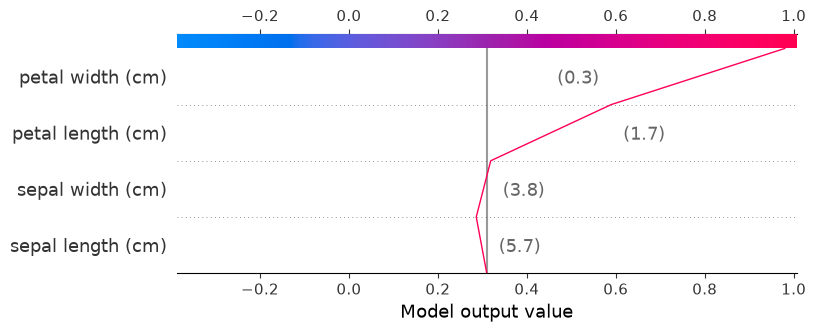

In [41]:
shap.decision_plot(explainer.expected_value[0], shap_values[:, 0], X_test.iloc[instancia])

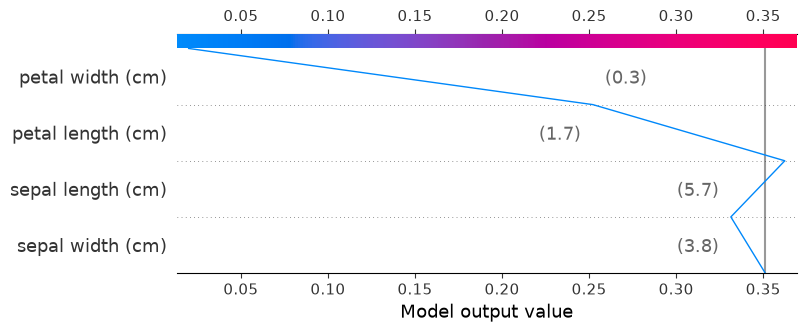

In [42]:
shap.decision_plot(explainer.expected_value[1], shap_values[:, 1], X_test.iloc[instancia])

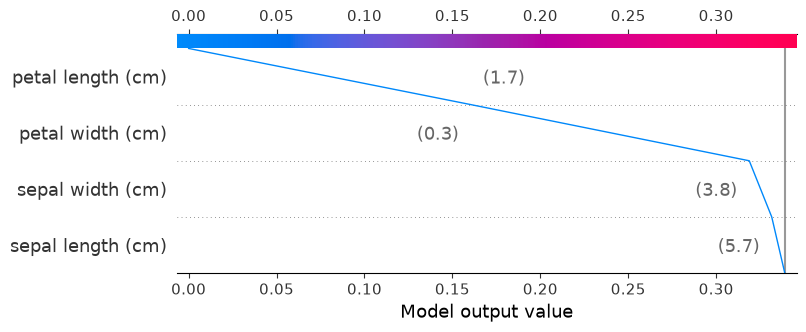

In [43]:
shap.decision_plot(explainer.expected_value[2], shap_values[:, 2], X_test.iloc[instancia])

In [44]:
explainer.shap_values

<bound method TreeExplainer.shap_values of <shap.explainers._tree.TreeExplainer object at 0x1597ad880>>

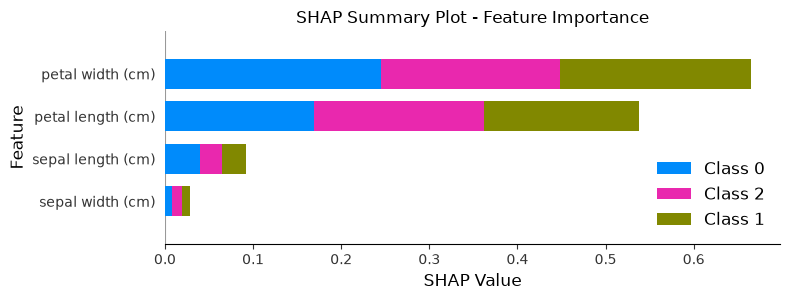

In [45]:
# Create a summary plot with the bar plot type
shap.summary_plot(explainer.shap_values(X_test), X_test, plot_type='bar', show=False)

# Customize the plot appearance
plt.title("SHAP Summary Plot - Feature Importance")
plt.xlabel("SHAP Value", fontsize=12)
plt.ylabel("Feature", fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

In [46]:
explainer_a = shap.Explainer(clf)
shap_values_cat = explainer_a(X_test)

In [47]:
shap_values_cat.shape

(38, 4, 3)

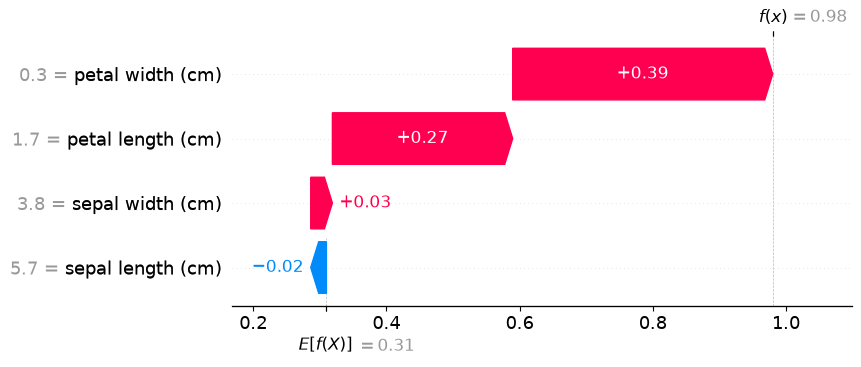

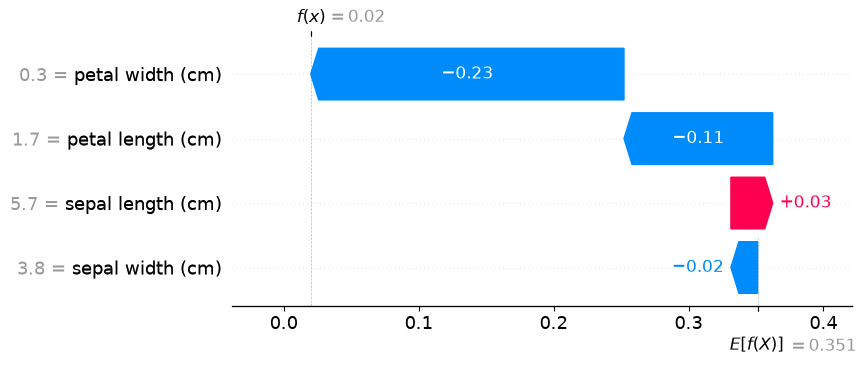

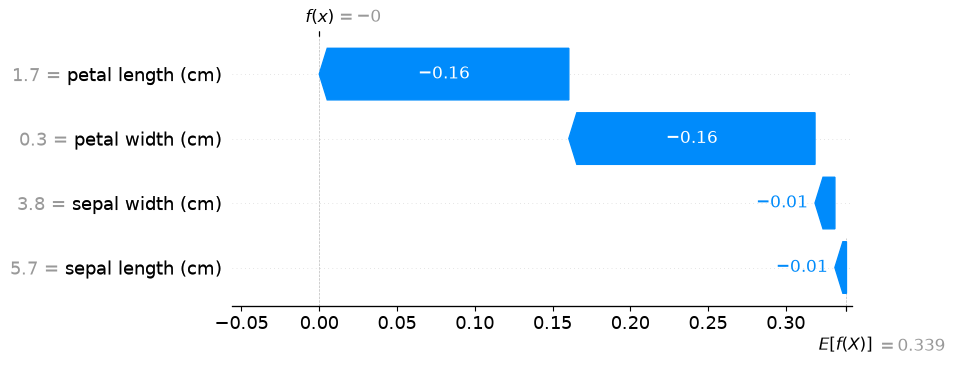

In [48]:
shap.plots.waterfall(shap_values_cat[i,:,0])
shap.plots.waterfall(shap_values_cat[i,:,1])
shap.plots.waterfall(shap_values_cat[i,:,2])